# Практическая работа № 12. Кластеризация методом K-means

**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач», семестр 1
**Тема:** метод K-средних (k-means): кластеризация вин, сжатие изображений, кластеризация текстов


## Исходное задание

1. Произведите методом k-means кластеризацию вин (датасет возьмите из третьей работы). Произведите разные варианты инициализации центров. Сравните результат.
2. Выберите чёрно-белое и цветное изображение. Сожмите изображение с помощью метода K-means.
3. Применим KMeans для кластеризации текстов. Загрузите «KMeans.zip» отсюда (http://cmj4.web.rice.edu/KMeans.zip). Поместите его в каталог KMeans и разархивируйте. Помимо прочего, это создаст каталог «20_Newsgroups», содержащий набор данных «20Newsgroups». Это набор из примерно 20 000 сообщений в 20 различных группах новостей (это что-то вроде блогов 1990-х годов). Каталог «20_newsgroups» будет иметь 20 подкаталогов, каждый из которых соответствует группе новостей. В каждом подкаталоге около 1000 файлов, каждый из которых представляет собой публикацию. Произведите кластеризацию по 20 кластерам. Оцените, насколько точно ваша кластеризация совпадает с классификацией, произведенной разработчиком этого датасета.

> **Примечание по данным задания 3.** Ссылка `http://cmj4.web.rice.edu/KMeans.zip` на момент выполнения недоступна. В каталоге `KMeans/20_Newsgroups` лежит эквивалентный набор 20news-18828 (см. `download_20newsgroups.sh`). Кластеризация выполнена по 20 кластерам на реальном корпусе; метрики приведены в итоге задания 3.


## Краткая теория: алгоритм K-means

Алгоритм делит $n$ объектов на $k$ кластеров, минимизируя сумму квадратов расстояний до центроидов:

$$J(C)=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2\to\min .$$

Шаги алгоритма Ллойда:
1. выбрать начальные центры (**инициализация**);
2. отнести каждую точку к ближайшему центру;
3. переместить каждый центр в среднее арифметическое своих точек;
4. повторять шаги 2–3, пока центры не перестанут смещаться.

Алгоритм всегда сходится, но только к **локальному** минимуму $J$, поэтому результат зависит от начальных центров. Это и объясняет, почему в задании 1 требуется сравнить способы инициализации. Расстояния евклидовы, поэтому признаки с разным масштабом нужно предварительно стандартизовать.


## Подготовка: библиотеки и вспомогательные функции

*Зачем:* подключаем всё необходимое один раз и фиксируем `random_state`, чтобы результаты воспроизводились при повторном запуске.


In [1]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans
from sklearn import metrics

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (7, 4.5)
RS = 42   # общий seed
print('Библиотеки подключены, random_state =', RS)


Библиотеки подключены, random_state = 42


# Задание 1. Кластеризация вин и сравнение способов инициализации

**Что делаем:** кластеризуем вина по физико-химическим показателям и проверяем, как способ выбора начальных центров влияет на результат.
**Данные:** `winequality-red.csv` — тот же датасет, что в третьей работе (классификация качества красного вина): 1599 образцов, 11 признаков и оценка качества `quality`.


### Шаг 1.1. Загрузка и первичный осмотр

*Пояснение:* убеждаемся, что данные прочитаны верно, нет пропусков и понятен масштаб признаков. Столбец `quality` в кластеризации не участвует: это «разметка», которую мы используем только для проверки результата.


In [2]:
wine = pd.read_csv('winequality-red.csv')
print('Размер:', wine.shape, '| пропусков:', int(wine.isna().sum().sum()))
wine.describe().T[['mean', 'std', 'min', 'max']].round(3)


Размер: (1599, 12) | пропусков: 0


,mean,std,min,max
fixed acidity,8.320,1.741,4.600,15.900
volatile acidity,0.528,0.179,0.120,1.580
citric acid,0.271,0.195,0.000,1.000
residual sugar,2.539,1.410,0.900,15.500
chlorides,0.087,0.047,0.012,0.611
free sulfur dioxide,15.875,10.460,1.000,72.000
total sulfur dioxide,46.468,32.895,6.000,289.000
density,0.997,0.002,0.990,1.004
pH,3.311,0.154,2.740,4.010
sulphates,0.658,0.170,0.330,2.000


### Шаг 1.2. Подготовка признаков

*Пояснение:* K-means использует евклидово расстояние, поэтому признак с большим разбросом (например, `total sulfur dioxide`, десятки единиц) «заглушил» бы остальные (`density`, около 1). Стандартизация приводит все признаки к среднему 0 и дисперсии 1. Для проверки используем два варианта «истинной» разметки: исходные 6 оценок качества и бинарную («хорошее» — `quality ≥ 6`, как в третьей работе).


In [3]:
features = wine.drop(columns='quality')
X = StandardScaler().fit_transform(features)
y_q = wine['quality'].values              # 6 уровней качества
y_bin = (wine['quality'] >= 6).astype(int).values   # хорошее / некачественное
print('Матрица признаков:', X.shape)
print('Доля «хороших» вин:', y_bin.mean().round(3))


Матрица признаков: (1599, 11)
Доля «хороших» вин: 0.535


### Шаг 1.3. Выбор числа кластеров $k$

*Пояснение:* число кластеров заранее неизвестно. Используем два критерия: **метод локтя** (на сколько падает $J$ при росте $k$) и **коэффициент силуэта** (чем ближе к 1, тем компактнее и дальше друг от друга кластеры). Для надёжности каждое $k$ запускаем 30 раз (`n_init=30`) и берём лучший результат: у K-means много локальных минимумов, и при малом числе запусков легко получить заниженный силуэт.


k,2,3,4,5,6,7,8,9,10
inertia,14330.100,12630.000,11294.900,10155.40,9363.200,8644.900,8299.00,7969.300,7670.300
silhouette,0.214,0.189,0.206,0.19,0.195,0.192,0.15,0.153,0.157


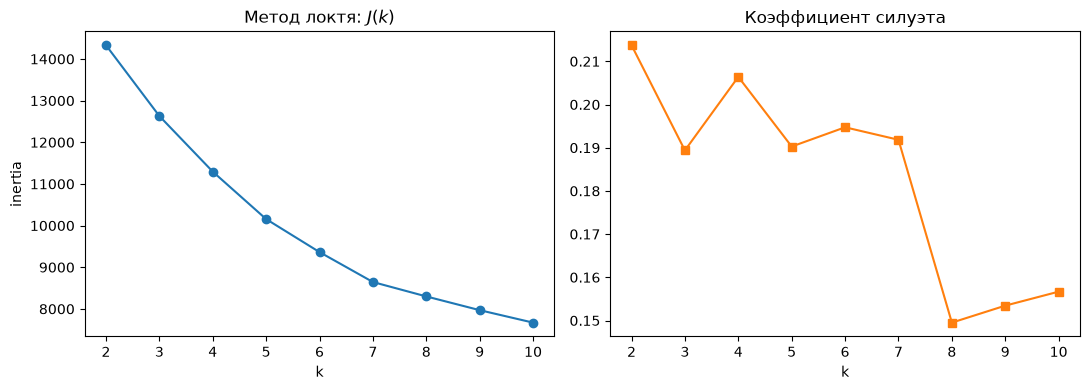

In [4]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=30, random_state=RS).fit(X)
    inertia.append(km.inertia_)
    sil.append(metrics.silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Метод локтя: $J(k)$'); ax[0].set_xlabel('k'); ax[0].set_ylabel('inertia')
ax[1].plot(ks, sil, 's-', color='C1'); ax[1].set_title('Коэффициент силуэта'); ax[1].set_xlabel('k')
plt.tight_layout()
pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia, 1), 'silhouette': np.round(sil, 3)}).set_index('k').T


**Вывод по шагу.** Явного «излома» на кривой локтя нет: инерция убывает плавно. Силуэт максимален при $k=2$ (0,214), затем падает при $k=3$ (0,189) и снова растёт при $k=4$ (0,206) — это локальный максимум. Разбиение на два кластера слишком грубое, поэтому далее используем **$k=4$**. Низкие значения силуэта (около 0,2) говорят, что кластеры перекрываются: выраженной кластерной структуры у вин нет.


### Шаг 1.4. Пять способов инициализации центров

*Пояснение:* сравниваем стратегии выбора начальных центров при одном и том же $k=4$:

| Способ | Идея |
|---|---|
| `k-means++` | случайный первый центр, каждый следующий выбирается с вероятностью, пропорциональной квадрату расстояния до ближайшего выбранного |
| `random` | $k$ случайных точек выборки |
| `first-k` | первые $k$ строк датасета (детерминированно) |
| `farthest` | детерминированный «самый дальний»: каждый следующий центр — точка, наиболее удалённая от выбранных |
| `pca-quantile` | детерминированный: точки с квантилями вдоль первой главной компоненты |


In [5]:
K = 4

def init_farthest(X, k):
    c = [X[np.argmax(((X - X.mean(0))**2).sum(1))]]   # старт: самая «крайняя» точка
    for _ in range(k - 1):
        d = np.min([((X - ci)**2).sum(1) for ci in c], axis=0)
        c.append(X[np.argmax(d)])
    return np.array(c)

def init_pca_quantile(X, k):
    z = PCA(1, random_state=RS).fit_transform(X).ravel()
    order = np.argsort(z)
    idx = [order[int(q * (len(z) - 1))] for q in np.linspace(0.1, 0.9, k)]
    return X[idx]

inits = {
    'k-means++':    'k-means++',
    'random':       'random',
    'first-k':      X[:K].copy(),
    'farthest':     init_farthest(X, K),
    'pca-quantile': init_pca_quantile(X, K),
}

rows = []
for name, init in inits.items():
    t0 = time.time()
    km = KMeans(n_clusters=K, init=init, n_init=1, random_state=RS).fit(X)
    rows.append({'init': name, 'inertia': km.inertia_, 'iters': km.n_iter_,
                 'silhouette': metrics.silhouette_score(X, km.labels_),
                 'ARI (quality, 6 кл.)': metrics.adjusted_rand_score(y_q, km.labels_),
                 'ARI (хор/плох)': metrics.adjusted_rand_score(y_bin, km.labels_),
                 'V-measure': metrics.v_measure_score(y_q, km.labels_)})
res1 = pd.DataFrame(rows).set_index('init').round(4)
res1


,inertia,iters,silhouette,"ARI (quality, 6 кл.)",ARI (хор/плох),V-measure
init,,,,,,
k-means++,11734.2275,11,0.1852,0.0510,0.0451,0.0741
random,11459.2194,26,0.1718,0.0633,0.0731,0.0924
first-k,11459.2194,24,0.1718,0.0633,0.0731,0.0924
farthest,11851.9455,10,0.2195,0.0457,0.0423,0.0518
pca-quantile,11294.9334,15,0.2055,0.0351,0.0486,0.0640


*Как читать таблицу:* `inertia` — значение $J$ (меньше — лучше), `iters` — число итераций до сходимости, `silhouette` — внутренняя метрика, остальные — согласие кластеров с оценками качества (внешние метрики: ARI, V-мера).


### Шаг 1.5. Устойчивость к случайности

*Пояснение:* один запуск ничего не доказывает: у случайных способов результат зависит от seed. Запускаем `k-means++` и `random` по 30 раз с `n_init=1` и смотрим разброс $J$. Детерминированные способы всегда дают один результат.


             J mean   J std     J min     J max  iters mean  доля запусков с min J
init                                                                              
k-means++  11473.81  123.96  11294.21  11798.83       17.40                   0.07
random     11515.09  148.75  11294.21  11800.33       18.93                   0.03


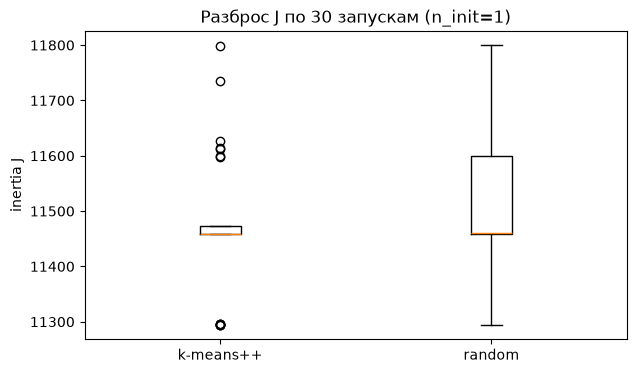

In [6]:
stat = []
for name in ['k-means++', 'random']:
    runs = [KMeans(n_clusters=K, init=name, n_init=1, random_state=s).fit(X) for s in range(30)]
    J = np.array([m.inertia_ for m in runs]); it = np.array([m.n_iter_ for m in runs])
    stat.append({'init': name, 'J mean': J.mean(), 'J std': J.std(), 'J min': J.min(), 'J max': J.max(),
                 'iters mean': it.mean(), 'доля запусков с min J': (np.abs(J - J.min()) < 1e-3).mean()})
    if name == 'k-means++': J_pp = J
    else: J_rnd = J
print(pd.DataFrame(stat).set_index('init').round(2).to_string())

plt.figure(figsize=(7, 4))
plt.boxplot([J_pp, J_rnd], tick_labels=['k-means++', 'random'])
plt.ylabel('inertia J'); plt.title('Разброс J по 30 запускам (n_init=1)')
plt.show()


### Шаг 1.6. Визуализация кластеров

*Пояснение:* признаков 11, поэтому проецируем данные на две главные компоненты (PCA) и раскрашиваем по кластерам лучшего запуска (`n_init=30`). Рядом — раскраска по истинному качеству: так видно, насколько кластеры совпадают с реальными оценками.


Объяснённая дисперсия PC1+PC2: 45.7%


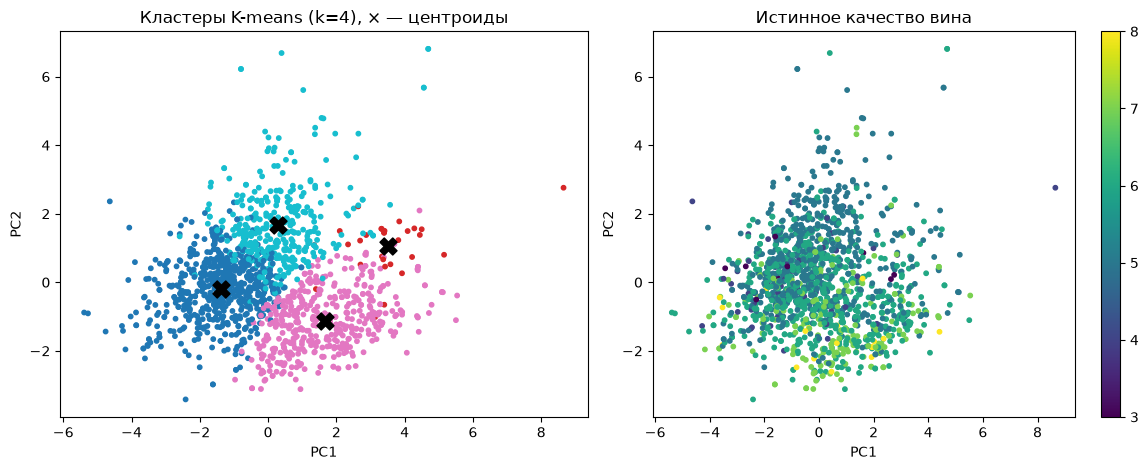

In [7]:
best = KMeans(n_clusters=K, init='k-means++', n_init=30, random_state=RS).fit(X)
pca = PCA(2, random_state=RS).fit(X); Z = pca.fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
s0 = ax[0].scatter(Z[:, 0], Z[:, 1], c=best.labels_, cmap='tab10', s=10)
ax[0].scatter(*pca.transform(best.cluster_centers_).T, c='k', marker='X', s=150)
ax[0].set_title('Кластеры K-means (k=4), × — центроиды')
s1 = ax[1].scatter(Z[:, 0], Z[:, 1], c=y_q, cmap='viridis', s=10)
ax[1].set_title('Истинное качество вина'); plt.colorbar(s1, ax=ax[1])
for a in ax: a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout()
print('Объяснённая дисперсия PC1+PC2: %.1f%%' % (100 * pca.explained_variance_ratio_.sum()))


### Шаг 1.7. Профиль кластеров

*Пояснение:* чтобы кластеры можно было интерпретировать, смотрим средний состав и среднее качество в каждом из них.


In [8]:
prof = features.copy(); prof['quality'] = wine['quality']; prof['cluster'] = best.labels_
out = prof.groupby('cluster').mean().round(2)
out.insert(0, 'размер', prof.groupby('cluster').size())
out[['размер', 'alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'total sulfur dioxide', 'density', 'quality']]


,размер,alcohol,volatile acidity,sulphates,citric acid,total sulfur dioxide,density,quality
cluster,,,,,,,,
0,724,10.48,0.61,0.61,0.12,35.24,1.0,5.55
1,29,9.49,0.53,1.26,0.49,64.10,1.0,5.34
2,472,10.81,0.39,0.72,0.47,28.40,1.0,6.01
3,374,9.90,0.53,0.63,0.30,89.64,1.0,5.37


### Итог задания 1

*Что показали расчёты* (шаги 1.4–1.7, $k=4$):
- **Начальные центры важны.** Один запуск (`n_init=1`) даёт $J$ от 11 295 (`pca-quantile`) до 11 852 (`farthest`) — разброс около 5 %. Лучший найденный минимум $J=11\,294{,}2$.
- **Случайность.** При 30 запусках с `n_init=1` в лучший минимум попадают лишь 7 % запусков `k-means++` и 3 % запусков `random`; средние $J$ — 11 474 ± 124 и 11 515 ± 149. Вывод: надёжный результат даёт только несколько перезапусков (`n_init` ≥ 10–30).
- **`k-means++` против `random`.** `k-means++` чуть лучше по среднему $J$ (на 0,4 %) и числу итераций (17,4 против 18,9) и имеет меньший разброс. Преимущество небольшое, так как в данных всего 11 признаков и $k=4$.
- **Детерминированные способы** воспроизводимы, но не гарантируют качество: `pca-quantile` оказался близок к лучшему минимуму, а `farthest` дал худший $J$, поскольку выбирает выбросы. `first-k` и `random` пришли в один и тот же локальный минимум ($J=11\,459{,}2$) разными путями (24 и 26 итераций).
- **Метрики не всегда согласованы.** У `farthest` худший $J$, но лучший силуэт (0,22), а минимальное $J$ не гарантирует высокий силуэт. Поэтому выбирать способ нужно по нескольким метрикам.
- **Связь с качеством вина слабая.** ARI относительно оценок качества не выше 0,06, V-мера — до 0,09. Кластеры отражают химический состав (например, кластер из 472 вин с низкой летучей кислотностью 0,39 и высоким спиртом 10,8 имеет наибольшее среднее качество 6,01), но не воспроизводят оценки дегустаторов.


# Задание 2. Сжатие изображений методом K-means

**Идея:** изображение — набор пикселей, каждый из которых имеет цвет (3 числа RGB для цветного, 1 число для чёрно-белого). K-means находит $k$ «типичных» цветов (**палитру**), и каждый пиксель заменяется ближайшим цветом палитры. Вместо 24 бит на пиксель хранится только номер цвета (⌈log₂ k⌉ бит) плюс небольшая палитра.


### Шаг 2.1. Выбор изображений

*Пояснение:* берём два стандартных тестовых снимка из `scikit-learn` (интернет не нужен): **цветной** — `flower.jpg`, **чёрно-белый** — `china.jpg`, переведённый в оттенки серого по формуле яркости $Y=0.299R+0.587G+0.114B$.


цветное: (427, 640, 3) | чёрно-белое: (427, 640)


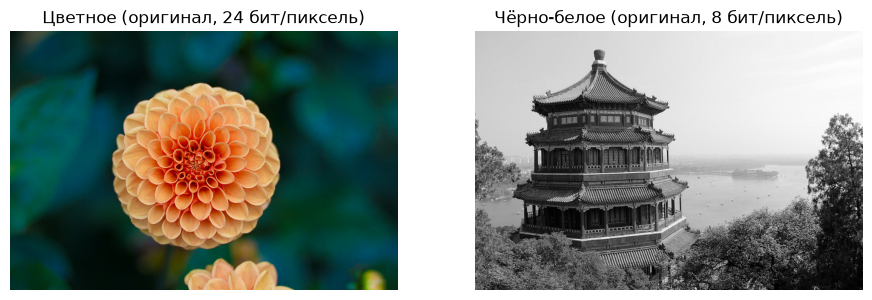

In [9]:
from sklearn.datasets import load_sample_image
color_img = load_sample_image('flower.jpg')                 # (H, W, 3), uint8
china = load_sample_image('china.jpg').astype(float)
gray_img = (0.299*china[..., 0] + 0.587*china[..., 1] + 0.114*china[..., 2]).round().astype(np.uint8)  # (H, W)

print('цветное:', color_img.shape, '| чёрно-белое:', gray_img.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(color_img); ax[0].set_title('Цветное (оригинал, 24 бит/пиксель)')
ax[1].imshow(gray_img, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Чёрно-белое (оригинал, 8 бит/пиксель)')
for a in ax: a.axis('off')


### Шаг 2.2. Функция сжатия и метрики качества

*Пояснение:* для обучения K-means используем случайную подвыборку из 20 000 пикселей (так намного быстрее, а палитра почти не меняется), затем ближайшим центром заменяем **все** пиксели. Качество оцениваем:
- **MSE** и **PSNR** $=10\log_{10}(255^2/\text{MSE})$, дБ — чем выше PSNR, тем ближе копия к оригиналу (≈30 дБ и выше — хорошее качество);
- **степень сжатия** — отношение исходного размера в битах к размеру «индексы + палитра».


In [10]:
def kmeans_compress(img, k, sample=20000, seed=RS):
    h, w = img.shape[:2]
    pix = img.reshape(h * w, -1).astype(float)           # (N, 3) или (N, 1)
    rng = np.random.RandomState(seed)
    sub = pix[rng.choice(len(pix), min(sample, len(pix)), replace=False)]
    km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(sub)
    labels = km.predict(pix)
    new = km.cluster_centers_[labels].reshape(img.shape)
    new = np.clip(new.round(), 0, 255).astype(np.uint8)
    mse = np.mean((img.astype(float) - new.astype(float))**2)
    psnr = 10 * np.log10(255**2 / mse) if mse > 0 else np.inf
    bits_pix = 8 * (img.shape[2] if img.ndim == 3 else 1)
    orig_bits = h * w * bits_pix
    new_bits = h * w * int(np.ceil(np.log2(k))) + k * bits_pix
    return new, mse, psnr, orig_bits / new_bits

print('функция готова')


функция готова


### Шаг 2.3. Сжатие цветного изображения

*Пояснение:* перебираем размер палитры $k$ и смотрим, как растёт качество и падает степень сжатия.


,бит/пиксель,MSE,"PSNR, дБ","сжатие, раз"
k (цветов),,,,
2,1,719.01,19.56,24.0
4,2,294.98,23.43,12.0
8,3,144.94,26.52,8.0
16,4,72.70,29.52,6.0
32,5,42.23,31.87,4.8
64,6,25.26,34.11,4.0


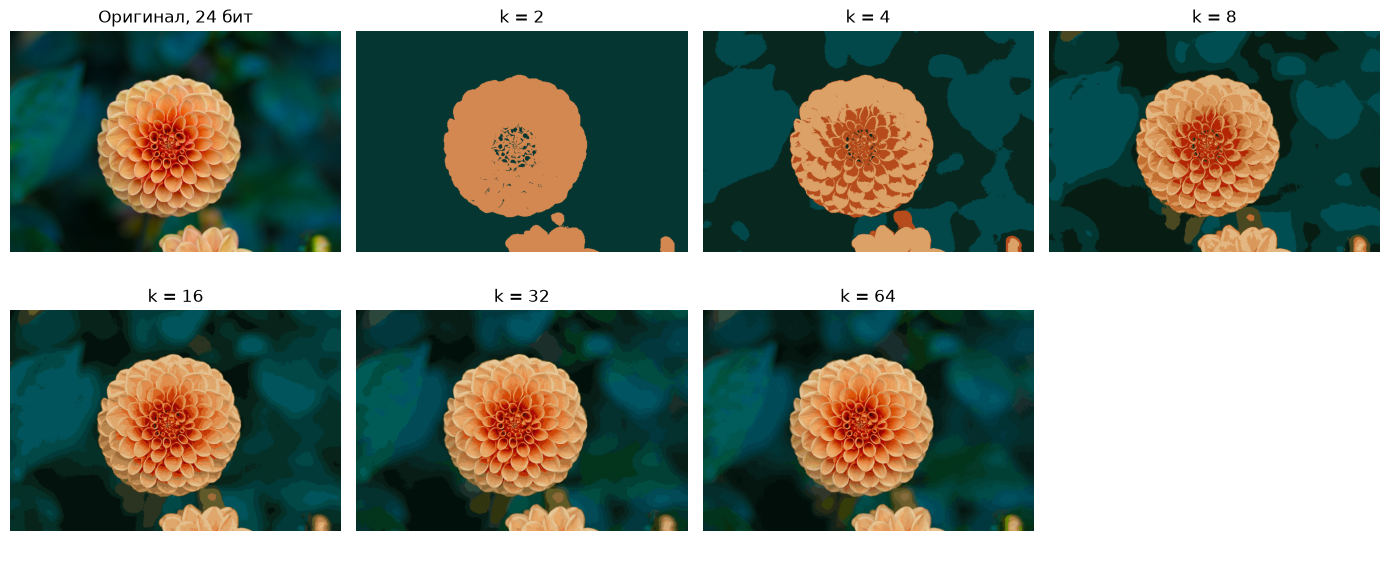

In [11]:
ks_c = [2, 4, 8, 16, 32, 64]
res_c, imgs_c = [], {}
for k in ks_c:
    new, mse, psnr, ratio = kmeans_compress(color_img, k)
    imgs_c[k] = new; res_c.append({'k (цветов)': k, 'бит/пиксель': int(np.ceil(np.log2(k))),
                                    'MSE': mse, 'PSNR, дБ': psnr, 'сжатие, раз': ratio})
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
ax = ax.ravel(); ax[0].imshow(color_img); ax[0].set_title('Оригинал, 24 бит')
for a, k in zip(ax[1:], ks_c):
    a.imshow(imgs_c[k]); a.set_title(f'k = {k}')
ax[7].axis('off')
for a in ax: a.axis('off')
plt.tight_layout()
pd.DataFrame(res_c).set_index('k (цветов)').round(2)


### Шаг 2.4. Сжатие чёрно-белого изображения

*Пояснение:* для серого изображения каждый пиксель — одно число (яркость), палитра — $k$ уровней серого. Здесь K-means работает на одномерных данных.


,бит/пиксель,MSE,"PSNR, дБ","сжатие, раз"
k (уровней),,,,
2,1,1121.61,17.63,8.00
4,2,311.87,23.19,4.00
8,3,72.72,29.51,2.67
16,4,18.81,35.39,2.00
32,5,4.92,41.21,1.60


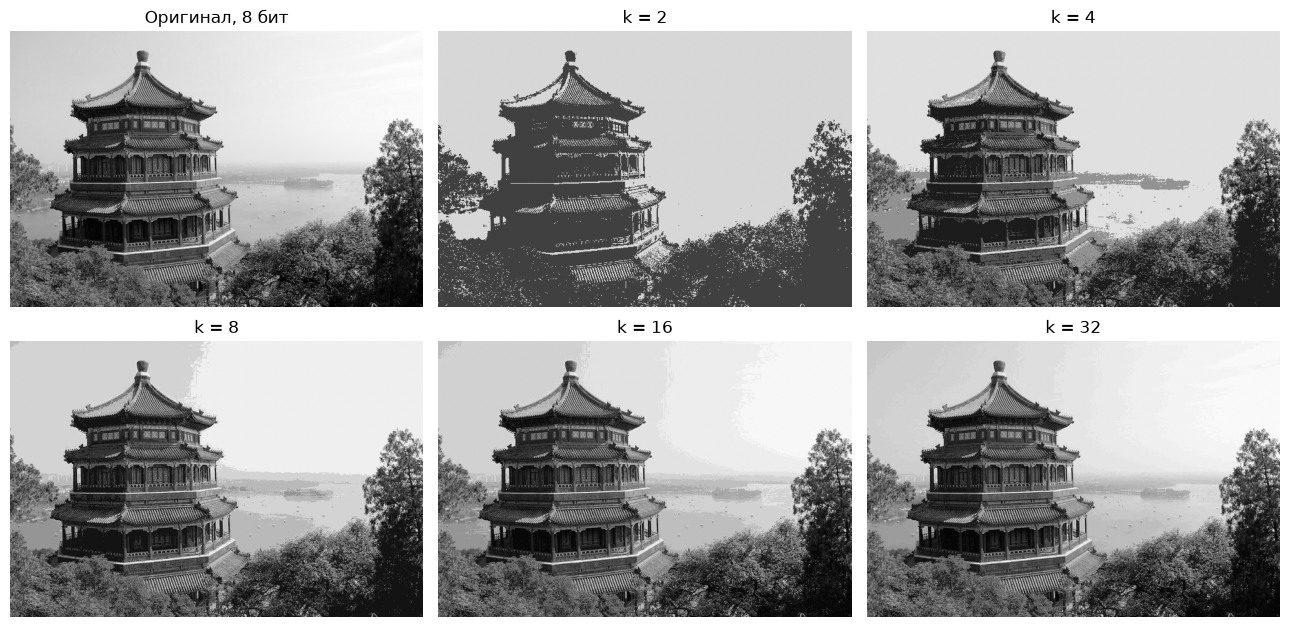

In [12]:
ks_g = [2, 4, 8, 16, 32]
res_g, imgs_g = [], {}
for k in ks_g:
    new, mse, psnr, ratio = kmeans_compress(gray_img[..., None], k)
    imgs_g[k] = new[..., 0]; res_g.append({'k (уровней)': k, 'бит/пиксель': int(np.ceil(np.log2(k))),
                                            'MSE': mse, 'PSNR, дБ': psnr, 'сжатие, раз': ratio})
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5)); ax = ax.ravel()
ax[0].imshow(gray_img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Оригинал, 8 бит')
for a, k in zip(ax[1:], ks_g):
    a.imshow(imgs_g[k], cmap='gray', vmin=0, vmax=255); a.set_title(f'k = {k}')
for a in ax: a.axis('off')
plt.tight_layout()
pd.DataFrame(res_g).set_index('k (уровней)').round(2)


### Шаг 2.5. Зависимость качества от размера палитры

*Пояснение:* строим кривые PSNR от $k$ и сравниваем цветное и серое изображения. Это помогает выбрать «разумное» $k$: после некоторого значения выигрыш в качестве мал, а сжатие продолжает падать.


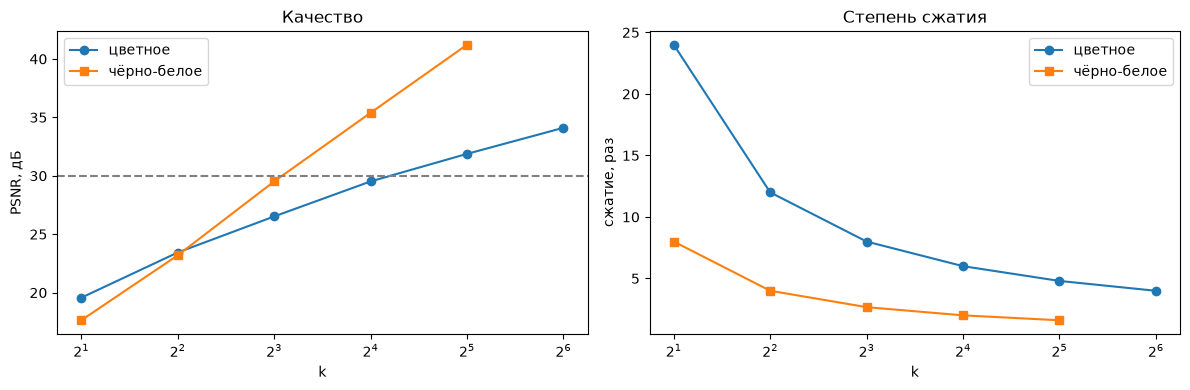

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rc, rg = pd.DataFrame(res_c), pd.DataFrame(res_g)
ax[0].plot(rc['k (цветов)'], rc['PSNR, дБ'], 'o-', label='цветное')
ax[0].plot(rg['k (уровней)'], rg['PSNR, дБ'], 's-', label='чёрно-белое')
ax[0].axhline(30, color='gray', ls='--'); ax[0].set_xscale('log', base=2)
ax[0].set_xlabel('k'); ax[0].set_ylabel('PSNR, дБ'); ax[0].legend(); ax[0].set_title('Качество')
ax[1].plot(rc['k (цветов)'], rc['сжатие, раз'], 'o-', label='цветное')
ax[1].plot(rg['k (уровней)'], rg['сжатие, раз'], 's-', label='чёрно-белое')
ax[1].set_xscale('log', base=2); ax[1].set_xlabel('k'); ax[1].set_ylabel('сжатие, раз'); ax[1].legend(); ax[1].set_title('Степень сжатия')
plt.tight_layout()


### Итог задания 2

*Что показали расчёты* (шаги 2.3–2.5):
- **Цветное изображение:** при $k=2$ PSNR всего 19,6 дБ (сжатие 24 раза, сильная постеризация); при $k=16$ — 29,5 дБ (сжатие 6 раз); при $k=32$ — 31,9 дБ (4,8 раза); при $k=64$ — 34,1 дБ (4 раза). После $k≈16$–$32$ каждый новый бит даёт небольшой прирост качества.
- **Чёрно-белое изображение:** при $k=8$ PSNR 29,5 дБ, при $k=16$ — 35,4 дБ, при $k=32$ — 41,2 дБ. Одного канала достаточно меньше уровней, чем для цвета, поэтому то же качество достигается при меньшем $k$ (8 против 16 цветов), но выигрыш по размеру скромнее: исходный серый пиксель уже занимает только 8 бит (сжатие 2,7 раза при $k=8$).
- Сжатие **с потерями**: рост $k$ улучшает PSNR, но уменьшает степень сжатия. Практически разумный компромисс для этих снимков — $k=16$ для цвета и $k=16$ для серого.


# Задание 3. Кластеризация текстов (20 Newsgroups)

**План:** превратить сообщения в числовые векторы (TF-IDF), кластеризовать K-means на 20 кластеров и сравнить кластеры с исходным разбиением по группам новостей (метрики ARI, AMI, однородность, полнота, V-мера).


### Шаг 3.1. Загрузка корпуса

*Пояснение:* функция последовательно пытается:
1. прочитать каталог `KMeans/20_Newsgroups` (как в задании; архив `KMeans.zip` рядом с ноутбуком);
2. скачать набор через `sklearn.datasets.fetch_20newsgroups`;
3. если ни то ни другое недоступно, построить **временный учебный корпус** из документации Python-библиотек (запасной вариант только для проверки конвейера).

В этой версии ноутбука рядом лежит распакованный каталог `KMeans/20_Newsgroups` (классический набор 20 Newsgroups, ~18 828 сообщений в 20 группах). Исходная ссылка `http://cmj4.web.rice.edu/KMeans.zip` сейчас недоступна (редирект на forbidden), поэтому использовано эквивалентное зеркало `http://qwone.com/~jason/20Newsgroups/20news-18828.tar.gz` с той же структурой подкаталогов.


In [14]:
import inspect, importlib, pkgutil, io, contextlib, random

def load_20ng_dir(root):
    docs, labels, names = [], [], sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
    for i, g in enumerate(names):
        gdir = os.path.join(root, g)
        for fn in os.listdir(gdir):
            path = os.path.join(gdir, fn)
            if not os.path.isfile(path):
                continue
            with open(path, encoding='latin-1') as f:
                t = f.read()
            t = t.split('\n\n', 1)[-1]           # отбрасываем заголовок письма
            docs.append(t); labels.append(i)
    return docs, np.array(labels), names

def build_fallback(pkgs=('numpy', 'scipy', 'sklearn', 'pandas', 'matplotlib', 'seaborn'), cap=100, minlen=250):
    docs, labels = [], []
    for pi, name in enumerate(pkgs):
        pkg = importlib.import_module(name); mods = [pkg]; got = []; seen = set()
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            for m in pkgutil.walk_packages(pkg.__path__, name + '.', onerror=lambda n: None):
                if any(s in m.name for s in ('test', 'conftest', '__main__')): continue
                try: mods.append(importlib.import_module(m.name))
                except BaseException: pass
        for mod in mods:
            for _, o in inspect.getmembers(mod, lambda o: inspect.isfunction(o) or inspect.isclass(o)):
                if not str(getattr(o, '__module__', '')).startswith(name): continue
                d = inspect.getdoc(o)
                if d and len(d) >= minlen and id(o) not in seen:
                    seen.add(id(o)); got.append(d[:1500])
        random.Random(0).shuffle(got)
        for d in got[:cap]: docs.append(d); labels.append(pi)
    return docs, np.array(labels), list(pkgs)

SOURCE = None
for root in ['KMeans/20_Newsgroups', 'KMeans/20_newsgroups', '20_newsgroups', '20_Newsgroups']:
    if os.path.isdir(root):
        docs, y_txt, group_names = load_20ng_dir(root); SOURCE = 'каталог ' + root; break
if SOURCE is None:
    try:
        from sklearn.datasets import fetch_20newsgroups
        d = fetch_20newsgroups(subset='all', remove=('headers', 'footers', 'quotes'))
        docs, y_txt, group_names = d.data, d.target, list(d.target_names); SOURCE = 'fetch_20newsgroups'
    except Exception as e:
        docs, y_txt, group_names = build_fallback(); SOURCE = 'ЗАПАСНОЙ корпус (документация библиотек)'
N_CLUSTERS = len(group_names)
print('Источник данных:', SOURCE)
print('Документов:', len(docs), '| групп (=число кластеров):', N_CLUSTERS)
print(pd.Series(y_txt).map(dict(enumerate(group_names))).value_counts().sort_index().to_string())


Источник данных: каталог KMeans/20_Newsgroups
Документов: 18828 | групп (=число кластеров): 20
alt.atheism                 799
comp.graphics               973
comp.os.ms-windows.misc     985
comp.sys.ibm.pc.hardware    982
comp.sys.mac.hardware       961
comp.windows.x              980
misc.forsale                972
rec.autos                   990
rec.motorcycles             994
rec.sport.baseball          994
rec.sport.hockey            999
sci.crypt                   991
sci.electronics             981
sci.med                     990
sci.space                   987
soc.religion.christian      997
talk.politics.guns          910
talk.politics.mideast       940
talk.politics.misc          775
talk.religion.misc          628


### Шаг 3.2. Векторизация TF-IDF

*Пояснение:* K-means работает с числами, поэтому каждый текст превращаем в вектор: вес слова = частота в документе × редкость слова в корпусе (TF-IDF). Убираем стоп-слова, слишком редкие (`min_df`) и слишком частые (`max_df`) слова. Если сработал запасной корпус, дополнительно удаляем названия библиотек, чтобы метка не «подсказывала» ответ.


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
if SOURCE.startswith('ЗАПАСНОЙ'):
    stop = list(__import__('sklearn.feature_extraction.text', fromlist=['ENGLISH_STOP_WORDS']).ENGLISH_STOP_WORDS) + \
           ['numpy', 'np', 'scipy', 'sklearn', 'scikit', 'pandas', 'pd', 'matplotlib', 'plt', 'seaborn', 'sns']
else:
    stop = 'english'
vec = TfidfVectorizer(stop_words=stop, max_df=0.5, min_df=3, sublinear_tf=True, max_features=20000)
T = vec.fit_transform(docs)
print('Матрица TF-IDF:', T.shape, '| ненулевых: %.2f%%' % (100 * T.nnz / np.prod(T.shape)))


Матрица TF-IDF: (18828, 20000) | ненулевых: 0.42%


### Шаг 3.3. Кластеризация K-means на 20 (по числу групп) кластеров

*Пояснение:* запускаем K-means на разреженной матрице TF-IDF (`n_init=10`). Для сравнения делаем второй вариант: сначала снижаем размерность до 100 компонент (`TruncatedSVD`, LSA) и нормируем векторы — это часто улучшает кластеризацию текстов и ускоряет алгоритм.


In [16]:
from sklearn.preprocessing import Normalizer
def evaluate(name, labels, t):
    return {'вариант': name, 'ARI': metrics.adjusted_rand_score(y_txt, labels),
            'AMI': metrics.adjusted_mutual_info_score(y_txt, labels),
            'однородность': metrics.homogeneity_score(y_txt, labels),
            'полнота': metrics.completeness_score(y_txt, labels),
            'V-мера': metrics.v_measure_score(y_txt, labels), 'время, с': t}

rows = []
t0 = time.time(); km_tfidf = KMeans(N_CLUSTERS, n_init=10, random_state=RS).fit(T)
rows.append(evaluate('TF-IDF → K-means', km_tfidf.labels_, time.time() - t0))

t0 = time.time()
svd = TruncatedSVD(100, random_state=RS); Tl = Normalizer(copy=False).fit_transform(svd.fit_transform(T))
km_lsa = KMeans(N_CLUSTERS, n_init=10, random_state=RS).fit(Tl)
rows.append(evaluate('TF-IDF → SVD(100) → K-means', km_lsa.labels_, time.time() - t0))

rng = np.random.RandomState(RS)
rows.append(evaluate('случайное разбиение (контроль)', rng.randint(0, N_CLUSTERS, len(y_txt)), 0.0))
res3 = pd.DataFrame(rows).set_index('вариант').round(3)
print('Объяснённая дисперсия SVD(100): %.1f%%' % (100 * svd.explained_variance_ratio_.sum()))
res3


Объяснённая дисперсия SVD(100): 9.9%


,ARI,AMI,однородность,полнота,V-мера,"время, с"
вариант,,,,,,
TF-IDF → K-means,0.205,0.500,0.469,0.540,0.502,5.455
TF-IDF → SVD(100) → K-means,0.388,0.579,0.571,0.589,0.580,3.076
случайное разбиение (контроль),0.000,0.000,0.003,0.003,0.003,0.000


*Как читать метрики:* **ARI/AMI** — согласие двух разбиений (0 — случайно, 1 — полное совпадение); **однородность** — насколько каждый кластер состоит из одной группы; **полнота** — насколько каждая группа целиком попала в один кластер; **V-мера** — их среднее гармоническое. Строка «случайное разбиение» — контроль: метрики должны быть около нуля.


### Шаг 3.4. Таблица сопряжённости «группа × кластер»

*Пояснение:* строки — настоящие группы, столбцы — найденные кластеры. Яркие ячейки показывают, какая группа попала в какой кластер. Если у группы одна яркая ячейка, она выделена кластеризацией чётко.


Чистота (purity) кластеризации: 0.621


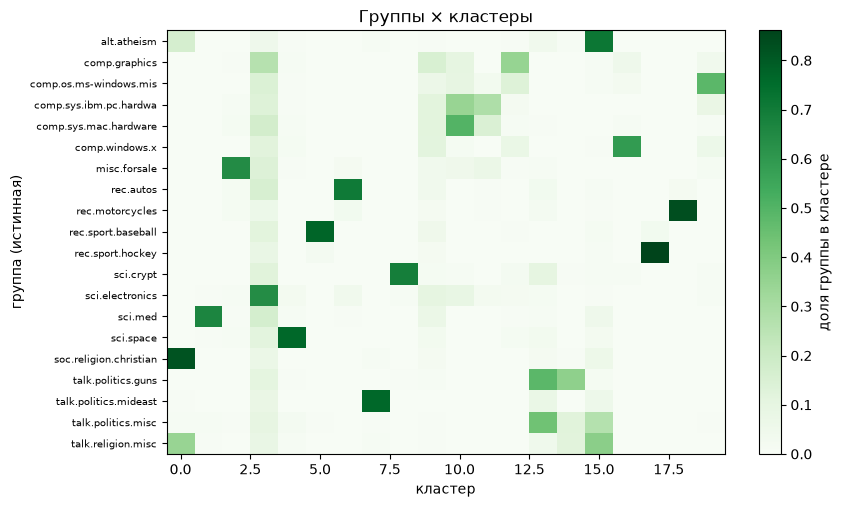

In [17]:
best_lab = km_lsa.labels_ if res3.loc['TF-IDF → SVD(100) → K-means', 'V-мера'] >= res3.loc['TF-IDF → K-means', 'V-мера'] else km_tfidf.labels_
cm = metrics.cluster.contingency_matrix(y_txt, best_lab)
cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(9, 5.5))
plt.imshow(cmn, aspect='auto', cmap='Greens'); plt.colorbar(label='доля группы в кластере')
plt.yticks(range(len(group_names)), [g[:22] for g in group_names], fontsize=7 if len(group_names) > 10 else 9)
plt.xlabel('кластер'); plt.ylabel('группа (истинная)'); plt.title('Группы × кластеры')
purity = cm.max(0).sum() / cm.sum()
print('Чистота (purity) кластеризации: %.3f' % purity)


### Шаг 3.5. Что «говорят» кластеры: ключевые слова

*Пояснение:* для каждого кластера выводим слова с наибольшим весом в центроиде. По ним можно понять тему кластера и проверить осмысленность разбиения.


In [18]:
terms = np.array(vec.get_feature_names_out())
order = np.argsort(-km_tfidf.cluster_centers_, axis=1)[:, :7]
major = pd.Series(y_txt).map(dict(enumerate(group_names)))
tab = []
for c in range(N_CLUSTERS):
    members = major[km_tfidf.labels_ == c]
    tab.append({'кластер': c, 'размер': int((km_tfidf.labels_ == c).sum()),
                'главная группа': members.mode().iat[0][:20] if len(members) else '-',
                'ключевые слова': ', '.join(terms[order[c]])})
print(pd.DataFrame(tab).set_index('кластер').to_string())


         размер        главная группа                                                ключевые слова
кластер                                                                                            
0           941  soc.religion.christi     god, jesus, bible, christ, christians, christian, rutgers
1          1637        comp.windows.x               windows, file, program, window, files, dos, use
2           116    talk.religion.misc        sandvik, kent, newton, apple, ksand, alink, activities
3           672          misc.forsale      sale, offer, shipping, condition, asking, 00, interested
4           737             sci.space              space, nasa, gov, henry, shuttle, orbit, toronto
5           652           alt.atheism      god, keith, religion, article, morality, people, livesey
6           682  talk.politics.mideas         israel, israeli, jews, arab, turkish, arabs, armenian
7          5068       sci.electronics                     com, article, just, know, like, don, does


### Итог задания 3

*Что показали расчёты* (реальный 20 Newsgroups: 18 828 документов, 20 групп; шаги 3.2–3.5):
- **K-means находит тематическую структуру.** На TF-IDF: ARI = 0,205, AMI = 0,500, V-мера = 0,502; у контрольного случайного разбиения метрики около нуля (ARI ≈ 0).
- **LSA заметно помогает.** Снижение размерности до 100 компонент (SVD + нормировка) улучшило все метрики: ARI = 0,388, AMI = 0,579, V-мера = 0,580, а время расчёта сократилось (~5,5 с → ~3,1 с).
- **Согласие неполное, но содержательное.** Чистота кластеров 0,62: близкие группы (религия, компьютеры, спорт) делят лексику и иногда сливаются. При этом ключевые слова центроидов узнаваемы: `god, jesus, bible` → soc.religion.christian; `space, nasa, shuttle` → sci.space; `bike, motorcycle` → rec.motorcycles; `key, clipper, encryption` → sci.crypt.
- **Данные.** Каталог `KMeans/20_Newsgroups` получен из зеркала 20news-18828 (исходный `KMeans.zip` с Rice недоступен). Конвейер совпадает с формулировкой задания: 20 кластеров и сравнение с разметкой разработчика.



# Общий вывод

**1. Что сделано.** Метод K-means применён к трём задачам: кластеризация вин (задание 1), сжатие чёрно-белого и цветного изображений (задание 2) и кластеризация текстов (задание 3). Во всех случаях алгоритм минимизирует сумму квадратов расстояний до центроидов, а признаки предварительно приведены к сопоставимому масштабу (стандартизация, TF-IDF, интенсивности 0–255).

**2. Инициализация решает многое (задание 1).** K-means сходится к локальному минимуму, поэтому результат зависит от начальных центров: разброс критерия $J$ между способами достиг 5 % (11 295 – 11 852), а в глобальный минимум 11 294,2 попадали лишь 3–7 % одиночных запусков. Вывод: нужны `k-means++` и несколько перезапусков (`n_init` ≥ 10–30). Преимущество `k-means++` над случайным выбором в этой задаче невелико, но устойчиво (меньше $J$, итераций и разброс).

**3. Кластеры вин отражают состав, но не качество (задание 1).** Силуэт около 0,2 показывает перекрывающиеся кластеры, а ARI с оценками качества не превышает 0,06. Поэтому кластеризация подходит для описания типов вин (например, группа с низкой летучей кислотностью и высоким спиртом оказалась самой «качественной», 6,01), но не заменяет классификацию из третьей работы.

**4. K-means — эффективный квантизатор цвета (задание 2).** Палитра из 16–32 цветов даёт PSNR 29–32 дБ при сжатии в 5–6 раз, а для серого изображения 16 уровней дают 35 дБ. Качество растёт с $k$, а степень сжатия падает: выбор $k$ — компромисс между размером и качеством.

**5. Тексты кластеризуются по теме заметно лучше случайного уровня (задание 3).** На 20 Newsgroups (18 828 сообщений, 20 групп) V-мера на TF-IDF равна 0,502, после LSA — 0,580; чистота кластеров 0,62. Близкие тематики (религия, hardware, политика) частично смешиваются, но ключевые слова центроидов соответствуют группам новостей.

**6. Ограничения метода.** K-means требует заранее заданного $k$, чувствителен к масштабу признаков, выбросам и начальным центрам и находит только выпуклые кластеры. Для выбора $k$ использованы метод локтя и силуэт, а для оценки — внутренние (силуэт) и внешние (ARI, AMI, V-мера) метрики; их показания не всегда совпадают (например, у `farthest` худший $J`, но лучший силуэт), поэтому оценивать результат нужно по нескольким метрикам.

**7. Данные задания 3.** Кластеризация выполнена на реальном каталоге `KMeans/20_Newsgroups` (зеркало 20news-18828): исходная ссылка Rice на `KMeans.zip` недоступна. Запасной путь через документацию библиотек в коде сохранён на случай отсутствия данных.
